# R-MOVE · 02 · ¿Cómo es la movilidad habitual y con qué se compara un día de incidencia?

**Respuesta corta: la movilidad tiene un patrón semanal y estacional muy marcado, y una referencia sencilla (la mediana del mismo día de la semana) no basta para distinguir una incidencia de un día raro.**

- **3.687 millones de viajes** entre municipios en 971 días (≈ 3,8 millones al día; faltan 3 días, notebook 01).
- **Día de la semana:** los domingos se viaja un −38,8 % menos que los jueves, y los lunes son los laborables más variables (sección 1.3).
- **Mes:** en agosto se viaja ≈ 24 % menos que el resto del año, los tres años; Semana Santa y Navidad también se notan (sección 1.4).
- **Territorio:** el 39 % de los viajes empiezan o acaban en Barcelona; las relaciones más grandes son las de Barcelona con L'Hospitalet, El Prat y Badalona (sección 2).
- **Primera referencia:** la mediana de los mismos días de la semana de las seis semanas anteriores es la mejor de tres referencias sencillas (error del 8,4 %, frente al 9,0 % de la media y el 9,6 % del último día comparable; sección 3.2).
- **Pero se equivoca justo en los días raros:** sus mayores desviaciones en Mataró → Barcelona son Navidad, Semana Santa, un día con un error en los datos y días cuya referencia incluye festivos locales o ese mismo error (sección 3.3). Por eso el notebook 03 define los días normales con un calendario completo y añade un grupo de control.

## Cómo leer este notebook

**Objetivo.** Antes de medir el impacto de las incidencias hay que saber cómo es un día normal. Este notebook describe la
movilidad entre municipios de la provincia de Barcelona (cuándo y dónde se viaja) y prueba una **primera referencia de
«día normal»**: la mediana de los mismos días de la semana de las seis semanas anteriores. Sus resultados explican por
qué el notebook 03 usa un método más completo.

**Datos.**
- `movilidad_municipios.parquet` (notebook 01): viajes diarios entre municipios distintos, enero de 2023 – agosto de 2025.
  No identifica el medio de transporte ni la hora, y los flujos de menos de 15 viajes se publican como 0.
- Catálogo de incidencias del equipo (`RMOVE_Incidencias_Barcelona_Jul2024_Ago2025_v07.xlsx`) y festivos de Cataluña,
  para excluir días de la referencia.
- Funciones de `src/analysis/` (lectura del catálogo y cálculo de la referencia).

**Salida.** Ninguna: es un notebook exploratorio.

| Sección | Contenido |
|---|---|
| **A. Preparación** | Configuración y resumen de los datos |
| **1. En el tiempo** | Serie diaria, distribución, día de la semana y mes |
| **2. En el territorio** | Relaciones y municipios con más viajes |
| **3. Primera referencia** | La mediana del mismo día de la semana: regla, evaluación y caso Mataró → Barcelona |
| **4. Conclusiones** | Qué se aprende y qué cambia en el notebook 03 |

# A. Preparación

### A.1 Configuración

In [1]:
import sys
from pathlib import Path

import duckdb
import holidays
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
MOVILIDAD = ROOT / "data" / "processed" / "telefonica" / "movilidad_municipios.parquet"
INCIDENCIAS = ROOT / "data" / "raw" / "rodalies" / "RMOVE_Incidencias_Barcelona_Jul2024_Ago2025_v07.xlsx"
sys.path.insert(0, str(ROOT / "src"))
from analysis.rmove_general import cargar_catalogo
from analysis.rmove_indicators import MESES_EXCLUIDOS, cargar_relaciones, evaluar_mediana, metricas_referencia

DIAS_SEMANA = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
ANOS = [2023, 2024, 2025]
con = duckdb.connect()
miles = lambda v: f"{v:,.0f}".replace(",", ".")

### A.2 Los datos

Se consulta el fichero con DuckDB, sin cargar sus 65 millones de filas en memoria, y se calcula el total de viajes de
cada día, que se usa en toda la sección 1.

In [2]:
resumen = con.execute(f"""
    SELECT COUNT(*) AS filas, MIN(day) AS primer_dia, MAX(day) AS ultimo_dia,
           COUNT(DISTINCT day) AS dias, SUM(viajes) AS viajes
    FROM read_parquet('{MOVILIDAD.as_posix()}')""").df()
display(resumen)
DIAS_DATOS = int(resumen.dias.iloc[0])

diaria = con.execute(f"""
    SELECT day, SUM(viajes) AS viajes FROM read_parquet('{MOVILIDAD.as_posix()}')
    GROUP BY day ORDER BY day""").df()
diaria["day"] = pd.to_datetime(diaria.day)
diaria["año"], diaria["mes"], diaria["dia_semana"] = diaria.day.dt.year, diaria.day.dt.month, diaria.day.dt.day_of_week

,filas,primer_dia,ultimo_dia,dias,viajes
0,64880151,2023-01-01,2025-08-31,971,3.686600e+09


**Resultado.** 64.880.151 filas entre el 01/01/2023 y el 31/08/2025, con datos en **971 días** (faltan 3; notebook 01) y **3.687 millones de viajes** en total.

# Resultados

## 1. La movilidad en el tiempo

### 1.1 Serie diaria

Total de viajes entre municipios de cada día, un gráfico por año con la misma escala. 2025 solo llega hasta agosto.

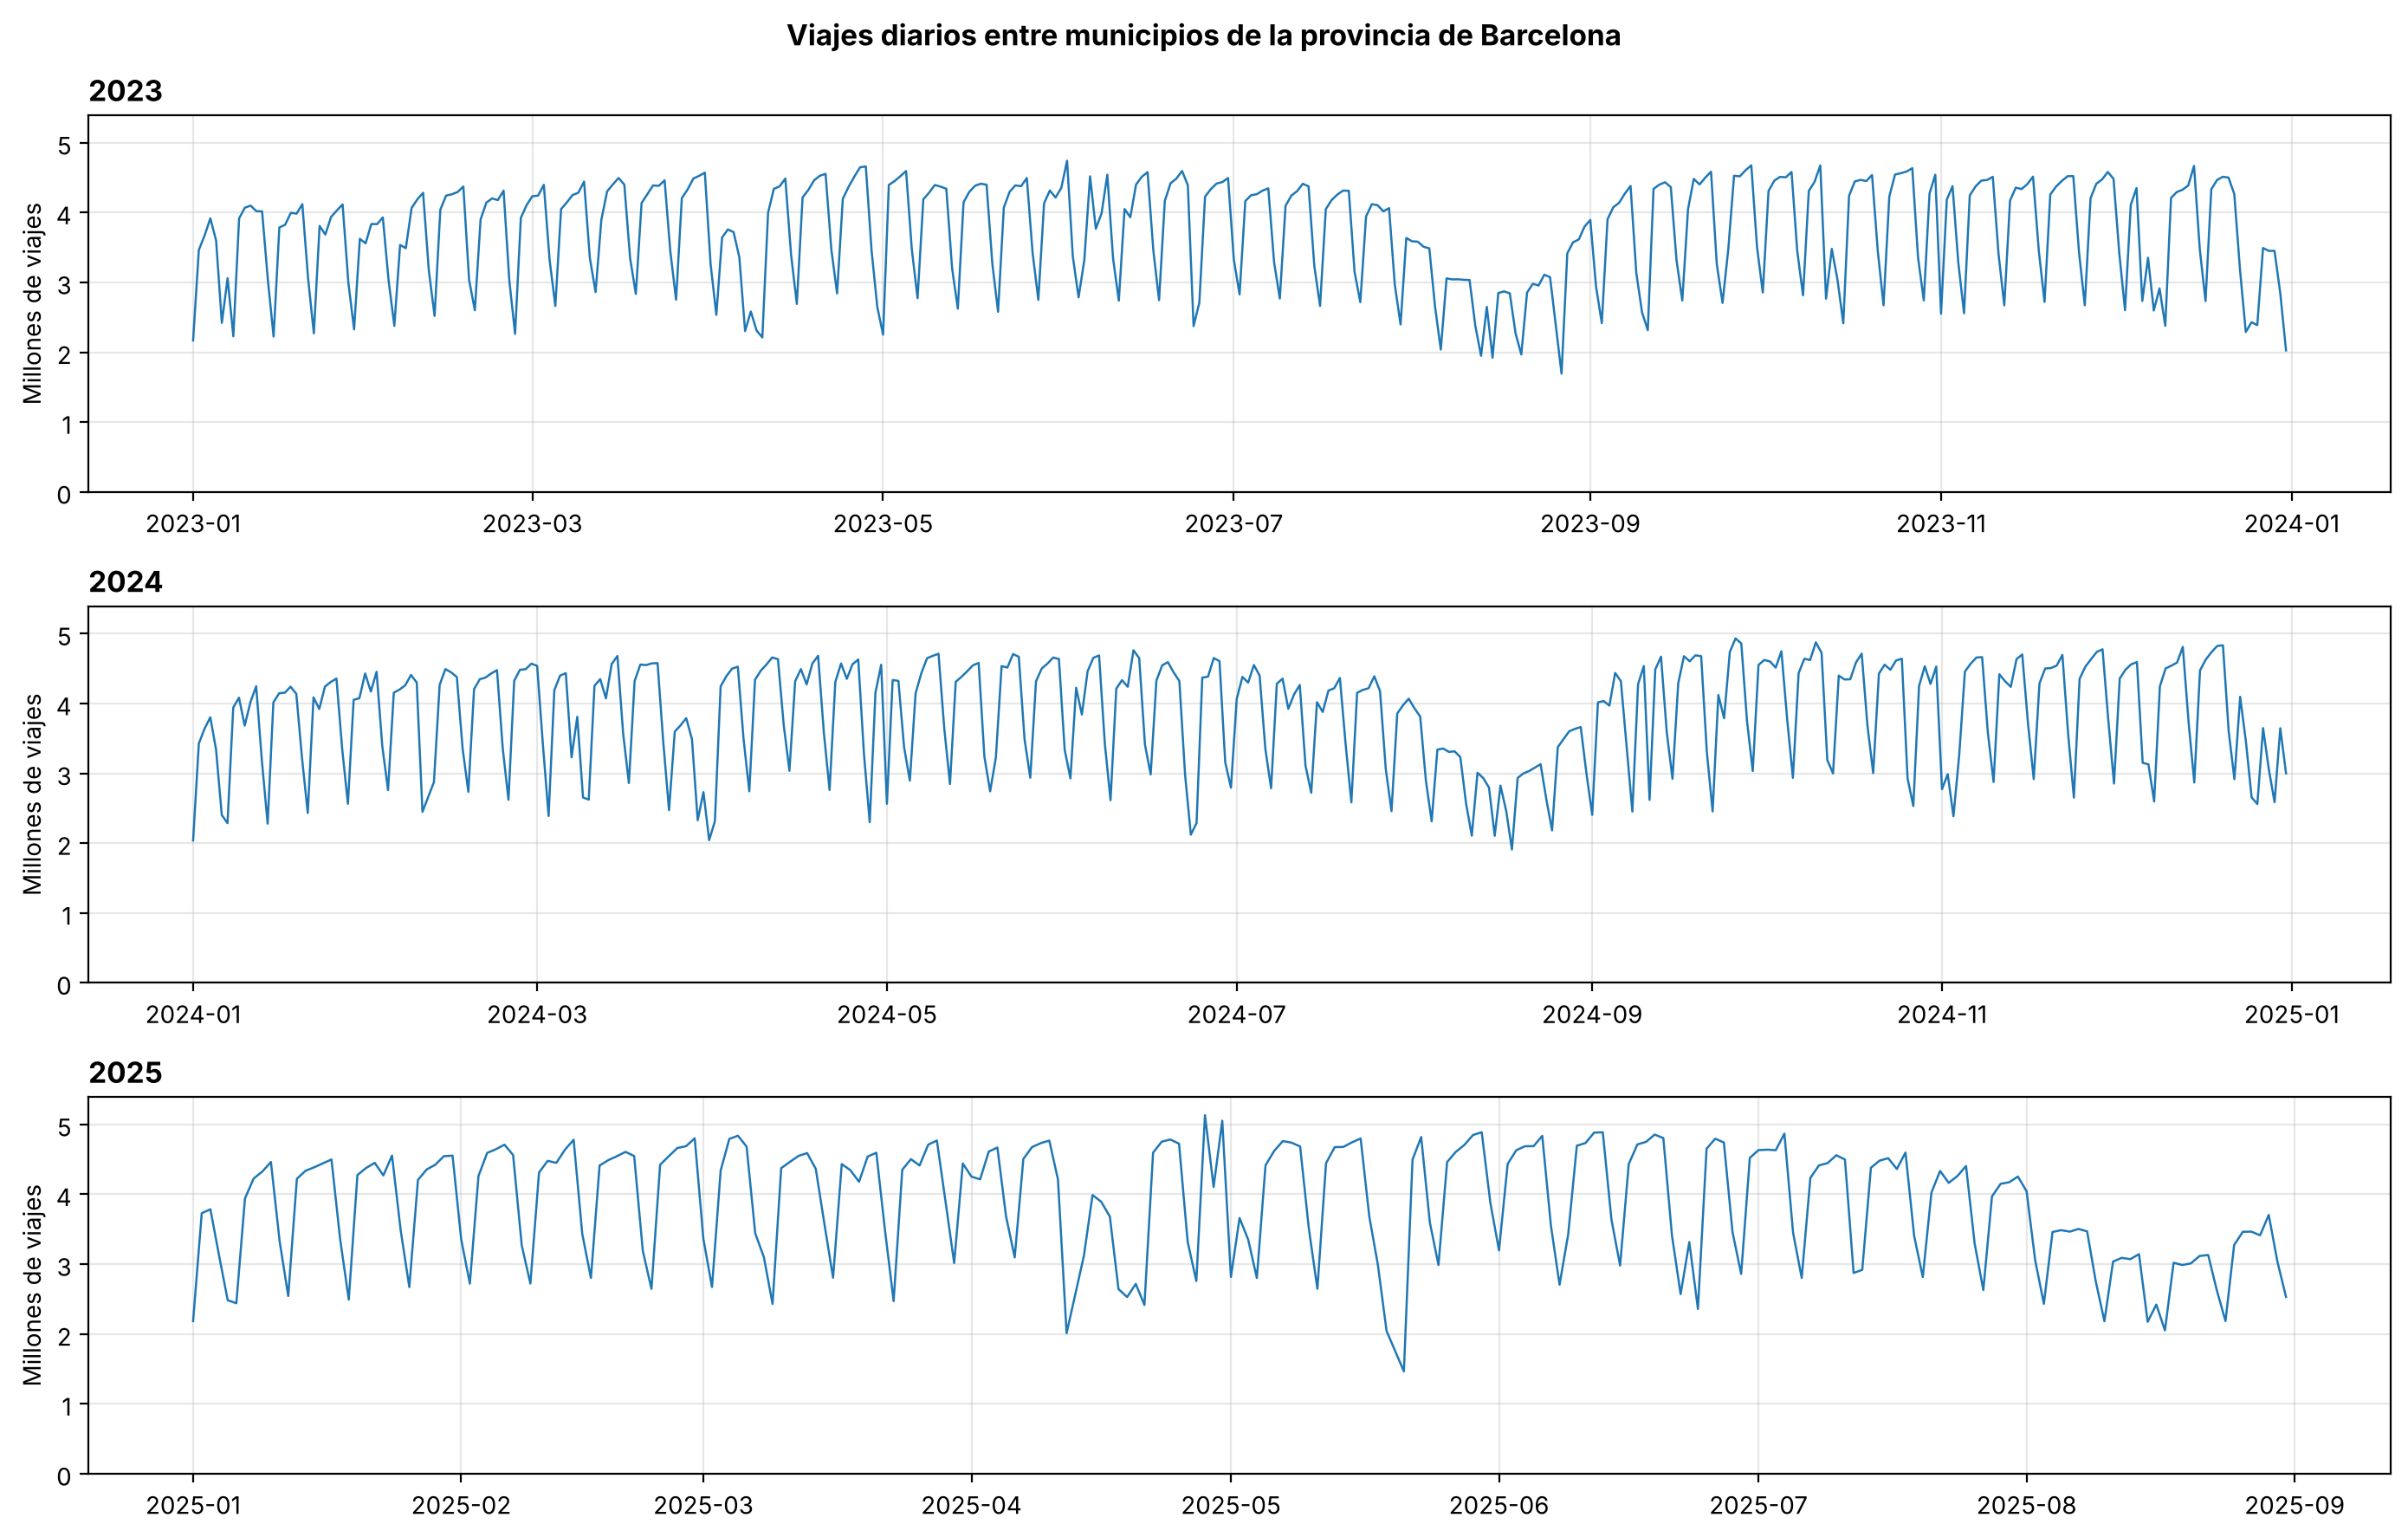

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharey=True)
for ax, a in zip(axes, ANOS):
    d = diaria[diaria.año == a]
    ax.plot(d.day, d.viajes / 1e6, lw=.9)
    ax.set_title(str(a), loc="left", fontweight="bold")
    ax.set_ylabel("Millones de viajes")
    ax.set_ylim(0, diaria.viajes.max() / 1e6 * 1.05)
    ax.grid(alpha=.3)
fig.suptitle("Viajes diarios entre municipios de la provincia de Barcelona", fontweight="bold")
plt.tight_layout()
plt.show()

**Resultado.** Los tres años repiten los mismos patrones: una oscilación semanal (muchos más viajes los laborables que los fines de semana), una caída fuerte en agosto y mínimos en Navidad y Semana Santa. Algunos días sueltos caen mucho más que los de su alrededor; en 2025 destacan el apagón del 28/04 y el 21/05, un día con un error en los datos (notebook 03, sección A.3). Ninguna caída se puede atribuir a Rodalies solo mirando la serie: hay que cruzarla con el calendario y las incidencias.

### 1.2 Distribución de los viajes diarios

Cada observación es un día (971), no una fila del fichero.

In [4]:
d = diaria.viajes.describe()
print(f"Media: {miles(d['mean'])} · mediana: {miles(d['50%'])} · desviación típica: {miles(d['std'])} "
      f"(coef. de variación {d['std'] / d['mean']:.1%})")
print(f"Mínimo: {miles(d['min'])} · máximo: {miles(d['max'])} · 50 % central: {miles(d['25%'])} – {miles(d['75%'])}")

Media: 3.796.704 · mediana: 4.112.409 · desviación típica: 784.746 (coef. de variación 20.7%)
Mínimo: 1.465.533 · máximo: 5.133.535 · 50 % central: 3.127.009 – 4.451.290


**Resultado.** La media es de **3.796.704 viajes al día** y la mediana de **4.112.409**; la mitad central de los días está entre 3.127.009 y 4.451.290. La media queda por debajo de la mediana porque hay muchos días con poca movilidad (fines de semana, agosto, festivos). La variación entre días es grande (desviación típica de 784.746, un 20,7 % de la media): una media global no sirve como referencia de «día normal».

### 1.3 Día de la semana

Media y distribución de los viajes de cada día de la semana. En los diagramas de caja, la línea es la mediana, el
triángulo la media, la caja el 50 % central y los círculos los valores alejados.

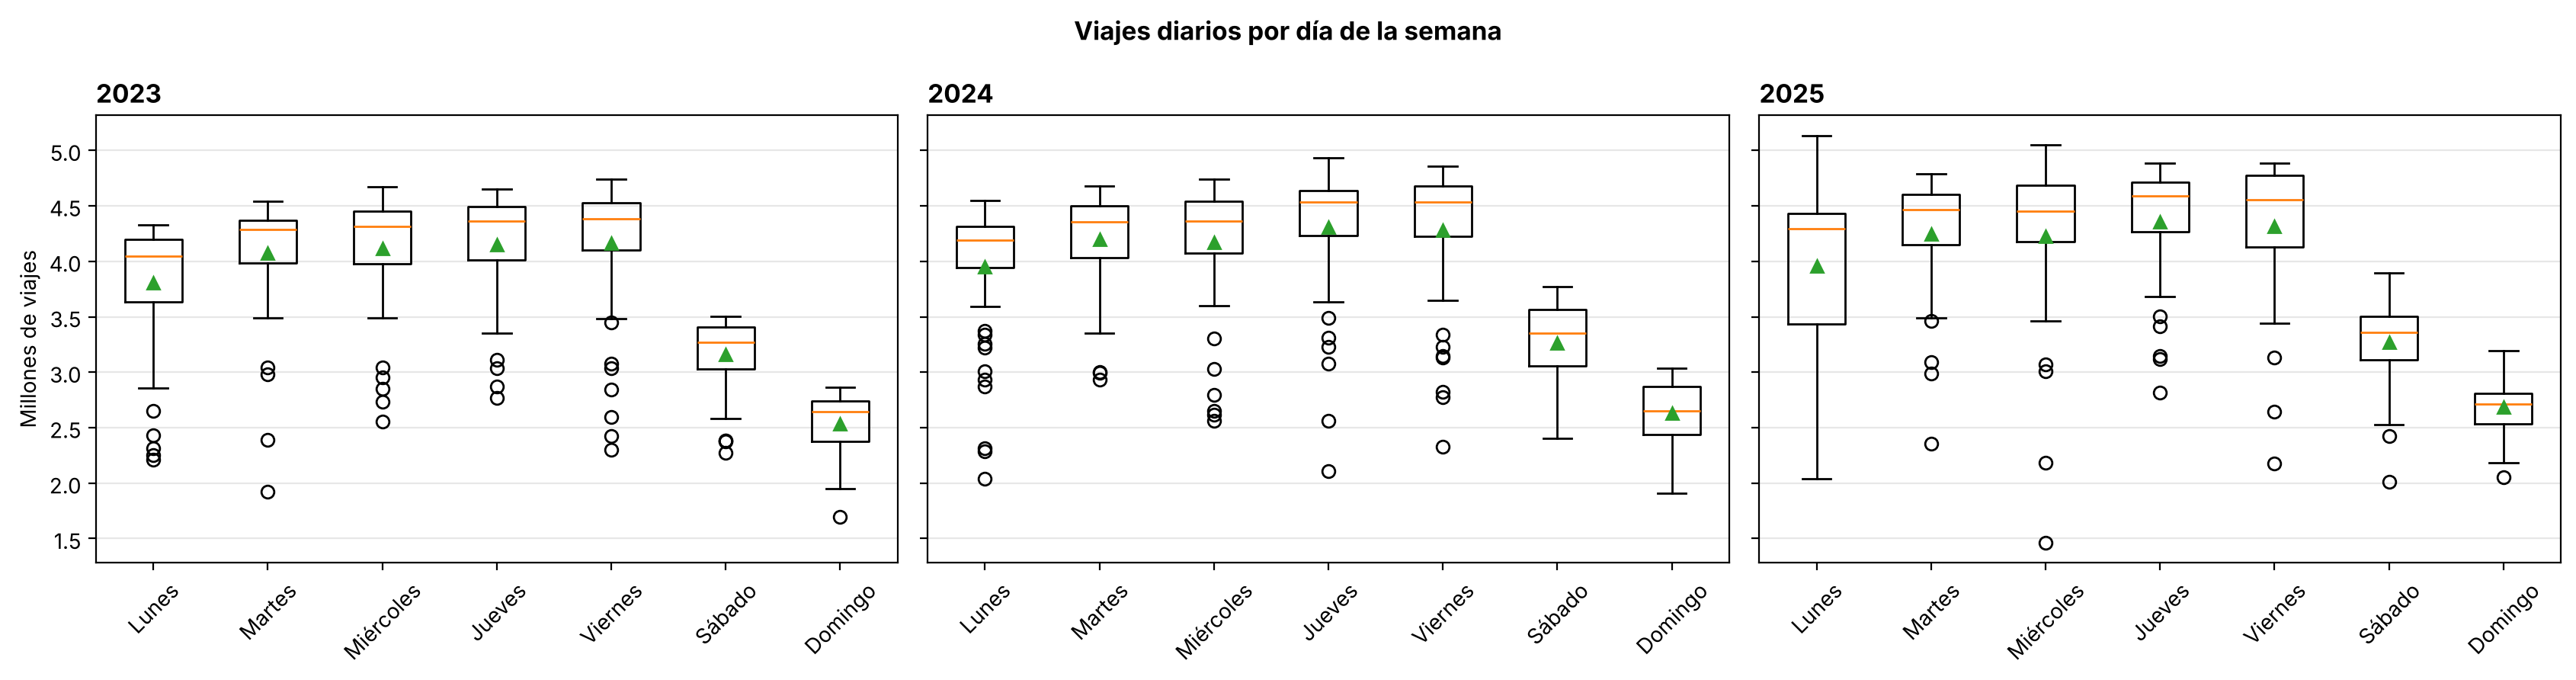

,dias,media,mediana,desviacion,cv_%
Lunes,139,3899911.0,4151639.0,621340.0,15.9
Martes,138,4162334.0,4338278.0,511510.0,12.3
Miércoles,139,4163764.0,4384373.0,599556.0,14.4
Jueves,139,4262562.0,4445155.0,540224.0,12.7
Viernes,139,4244912.0,4476912.0,621137.0,14.6
Sábado,139,3228881.0,3332818.0,361607.0,11.2
Domingo,138,2608648.0,2667416.0,279650.0,10.7


Domingo frente a jueves: 2.608.648 frente a 4.262.562 viajes (-38.8%)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, a in zip(axes, ANOS):
    d = diaria[diaria.año == a]
    ax.boxplot([d.loc[d.dia_semana == i, "viajes"] / 1e6 for i in range(7)], tick_labels=DIAS_SEMANA, showmeans=True)
    ax.set_title(str(a), loc="left", fontweight="bold")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("Millones de viajes")
fig.suptitle("Viajes diarios por día de la semana", fontweight="bold")
plt.tight_layout()
plt.show()

semana = diaria.groupby("dia_semana").viajes.agg(dias="count", media="mean", mediana="median", desviacion="std")
semana.index = DIAS_SEMANA
semana["cv_%"] = semana.desviacion / semana.media * 100
display(semana.round({"media": 0, "mediana": 0, "desviacion": 0, "cv_%": 1}))
j, dom = semana.loc["Jueves", "media"], semana.loc["Domingo", "media"]
print(f"Domingo frente a jueves: {miles(dom)} frente a {miles(j)} viajes ({dom / j - 1:+.1%})")

**Resultado.** Los laborables tienen ≈ 4,2 millones de viajes y los fines de semana bastantes menos: los domingos, **2,6 millones, un −38,8 % respecto a los jueves**. Los **lunes** son el laborable más variable (coeficiente de variación del 15,9 %, frente al 12–15 % del resto), probablemente porque muchos festivos y puentes caen en lunes. Conclusión: cada día solo se puede comparar con días del mismo tipo de la semana, y los laborables tienen valores atípicos (festivos, huelgas, errores) que hay que excluir de la referencia.

### 1.4 Mes del año

Media de viajes diarios de cada mes.

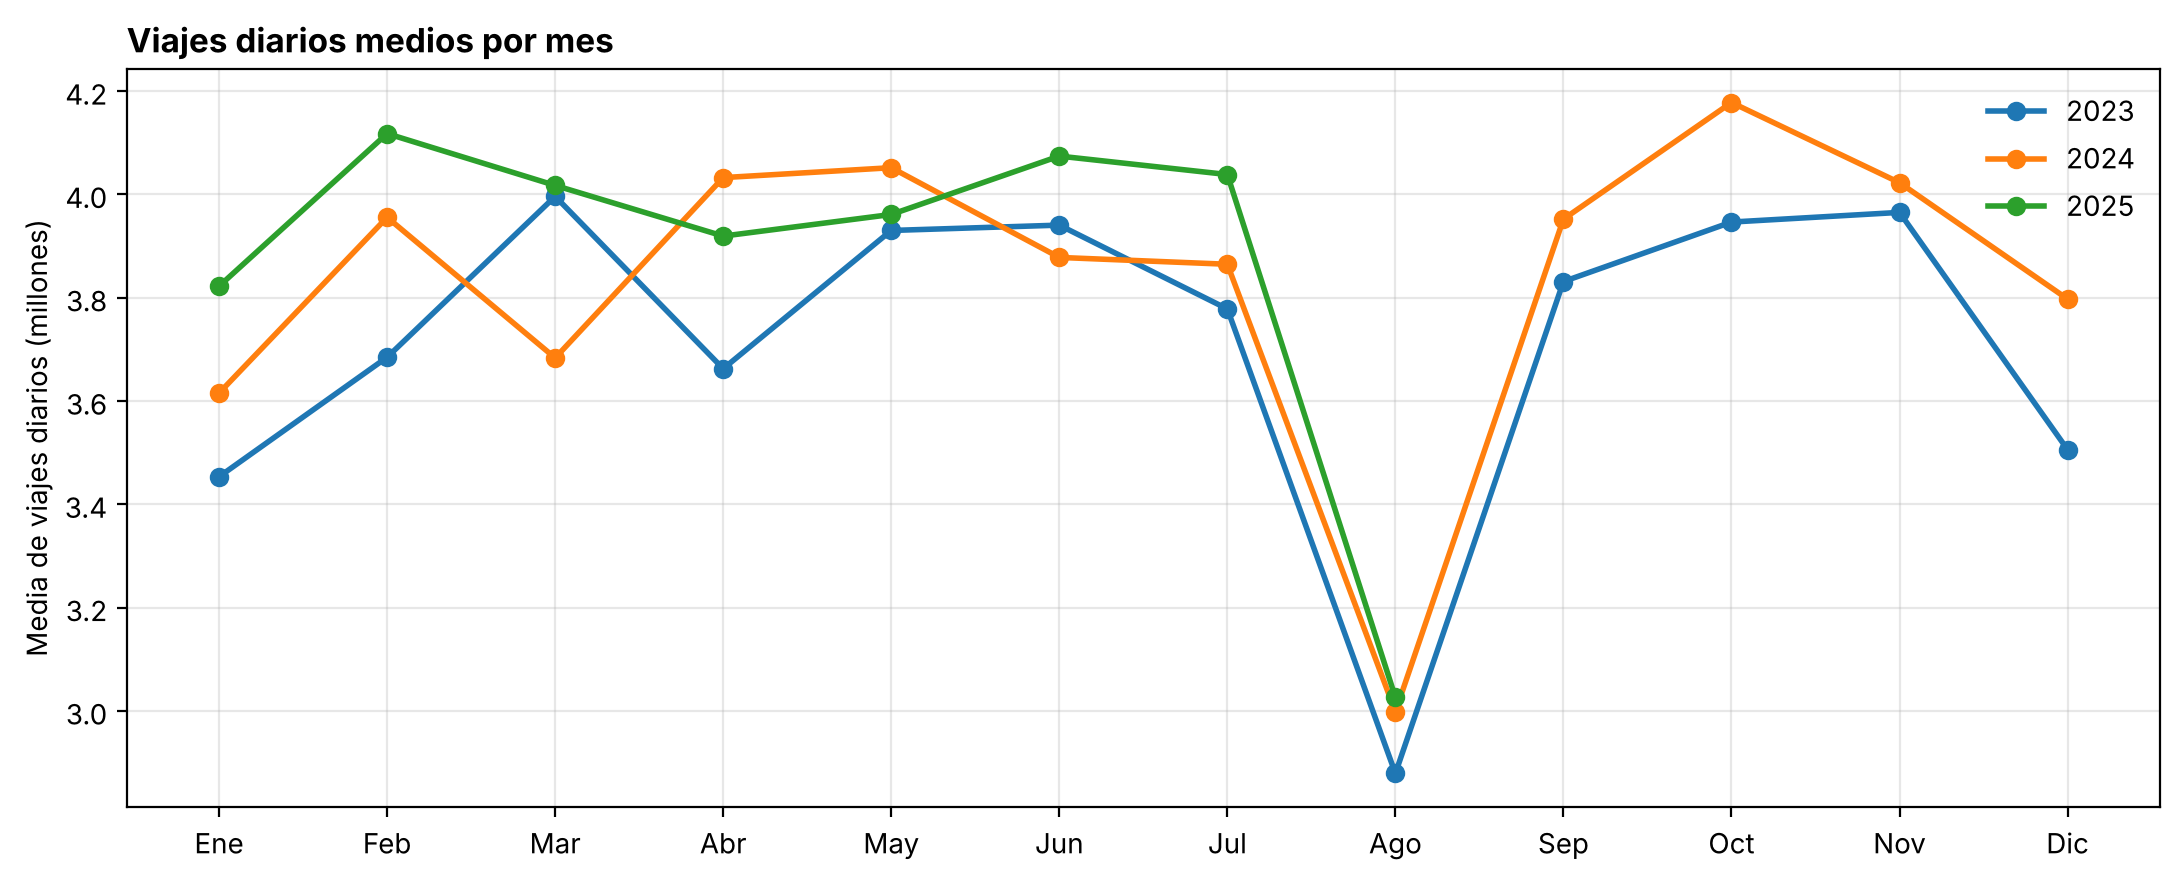

2023: agosto -24.0% respecto a la media de los demás meses
2024: agosto -23.4% respecto a la media de los demás meses
2025: agosto -24.2% respecto a la media de los demás meses


In [6]:
mensual = diaria.groupby(["año", "mes"]).viajes.mean().unstack("año")
fig, ax = plt.subplots(figsize=(11, 4.5))
for a in ANOS:
    ax.plot(mensual.index, mensual[a] / 1e6, marker="o", lw=2, label=str(a))
ax.set_xticks(range(1, 13), MESES)
ax.set_ylabel("Media de viajes diarios (millones)")
ax.set_title("Viajes diarios medios por mes", loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

for a in ANOS:
    resto = mensual.loc[[m for m in range(1, 13) if m != 8], a].mean()
    print(f"{a}: agosto {mensual.at[8, a] / resto - 1:+.1%} respecto a la media de los demás meses")

**Resultado.** En **agosto** se viaja un ≈ 24 % menos que el resto del año, igual los tres años (−24,0 %, −23,4 % y −24,2 %). Diciembre y enero también están por debajo (Navidad). Semana Santa mueve un mes cada año: por eso bajan abril de 2023 y marzo de 2024. La época del año cambia el volumen normal, así que la referencia tiene que tenerla en cuenta.

## 2. La movilidad en el territorio

### 2.1 Relaciones con más viajes

Viajes totales de cada relación origen → destino en el periodo y su media diaria (total / días con datos).

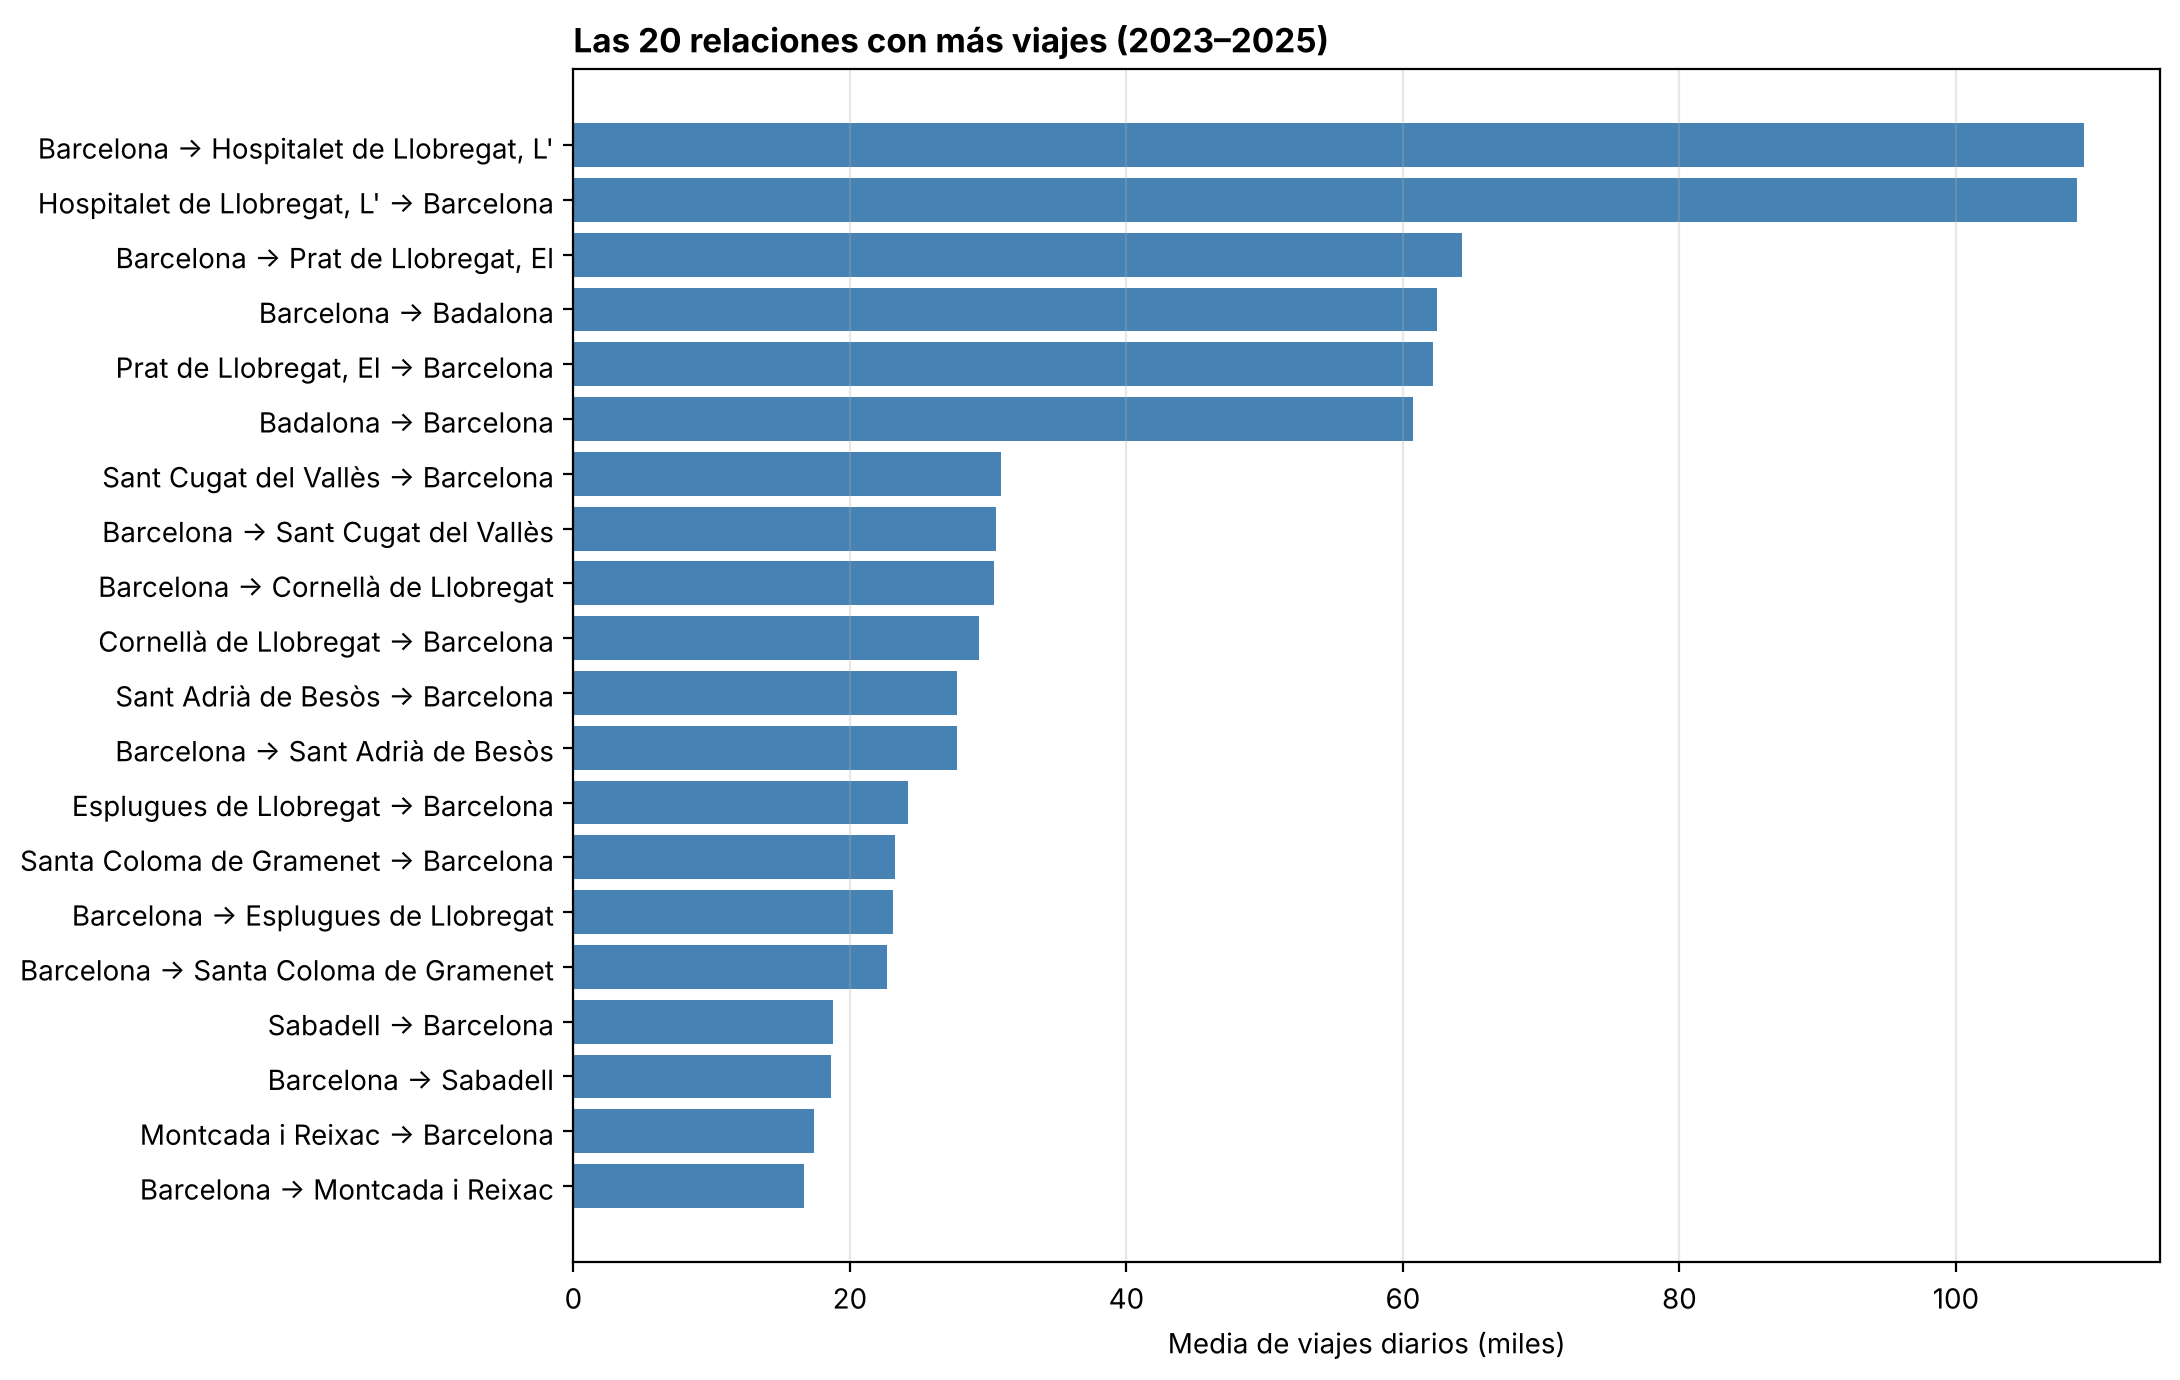

In [7]:
relaciones_top = con.execute(f"""
    SELECT municipio_origen_name || ' → ' || municipio_destino_name AS relacion,
           SUM(viajes) / {DIAS_DATOS} AS media_diaria
    FROM read_parquet('{MOVILIDAD.as_posix()}')
    GROUP BY municipio_origen_name, municipio_destino_name
    ORDER BY media_diaria DESC LIMIT 20""").df()

fig, ax = plt.subplots(figsize=(11, 7))
t = relaciones_top.iloc[::-1]
ax.barh(t.relacion, t.media_diaria / 1e3, color="steelblue")
ax.set_xlabel("Media de viajes diarios (miles)")
ax.set_title("Las 20 relaciones con más viajes (2023–2025)", loc="left", fontweight="bold")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()

### 2.2 Municipios con más viajes de salida y de llegada

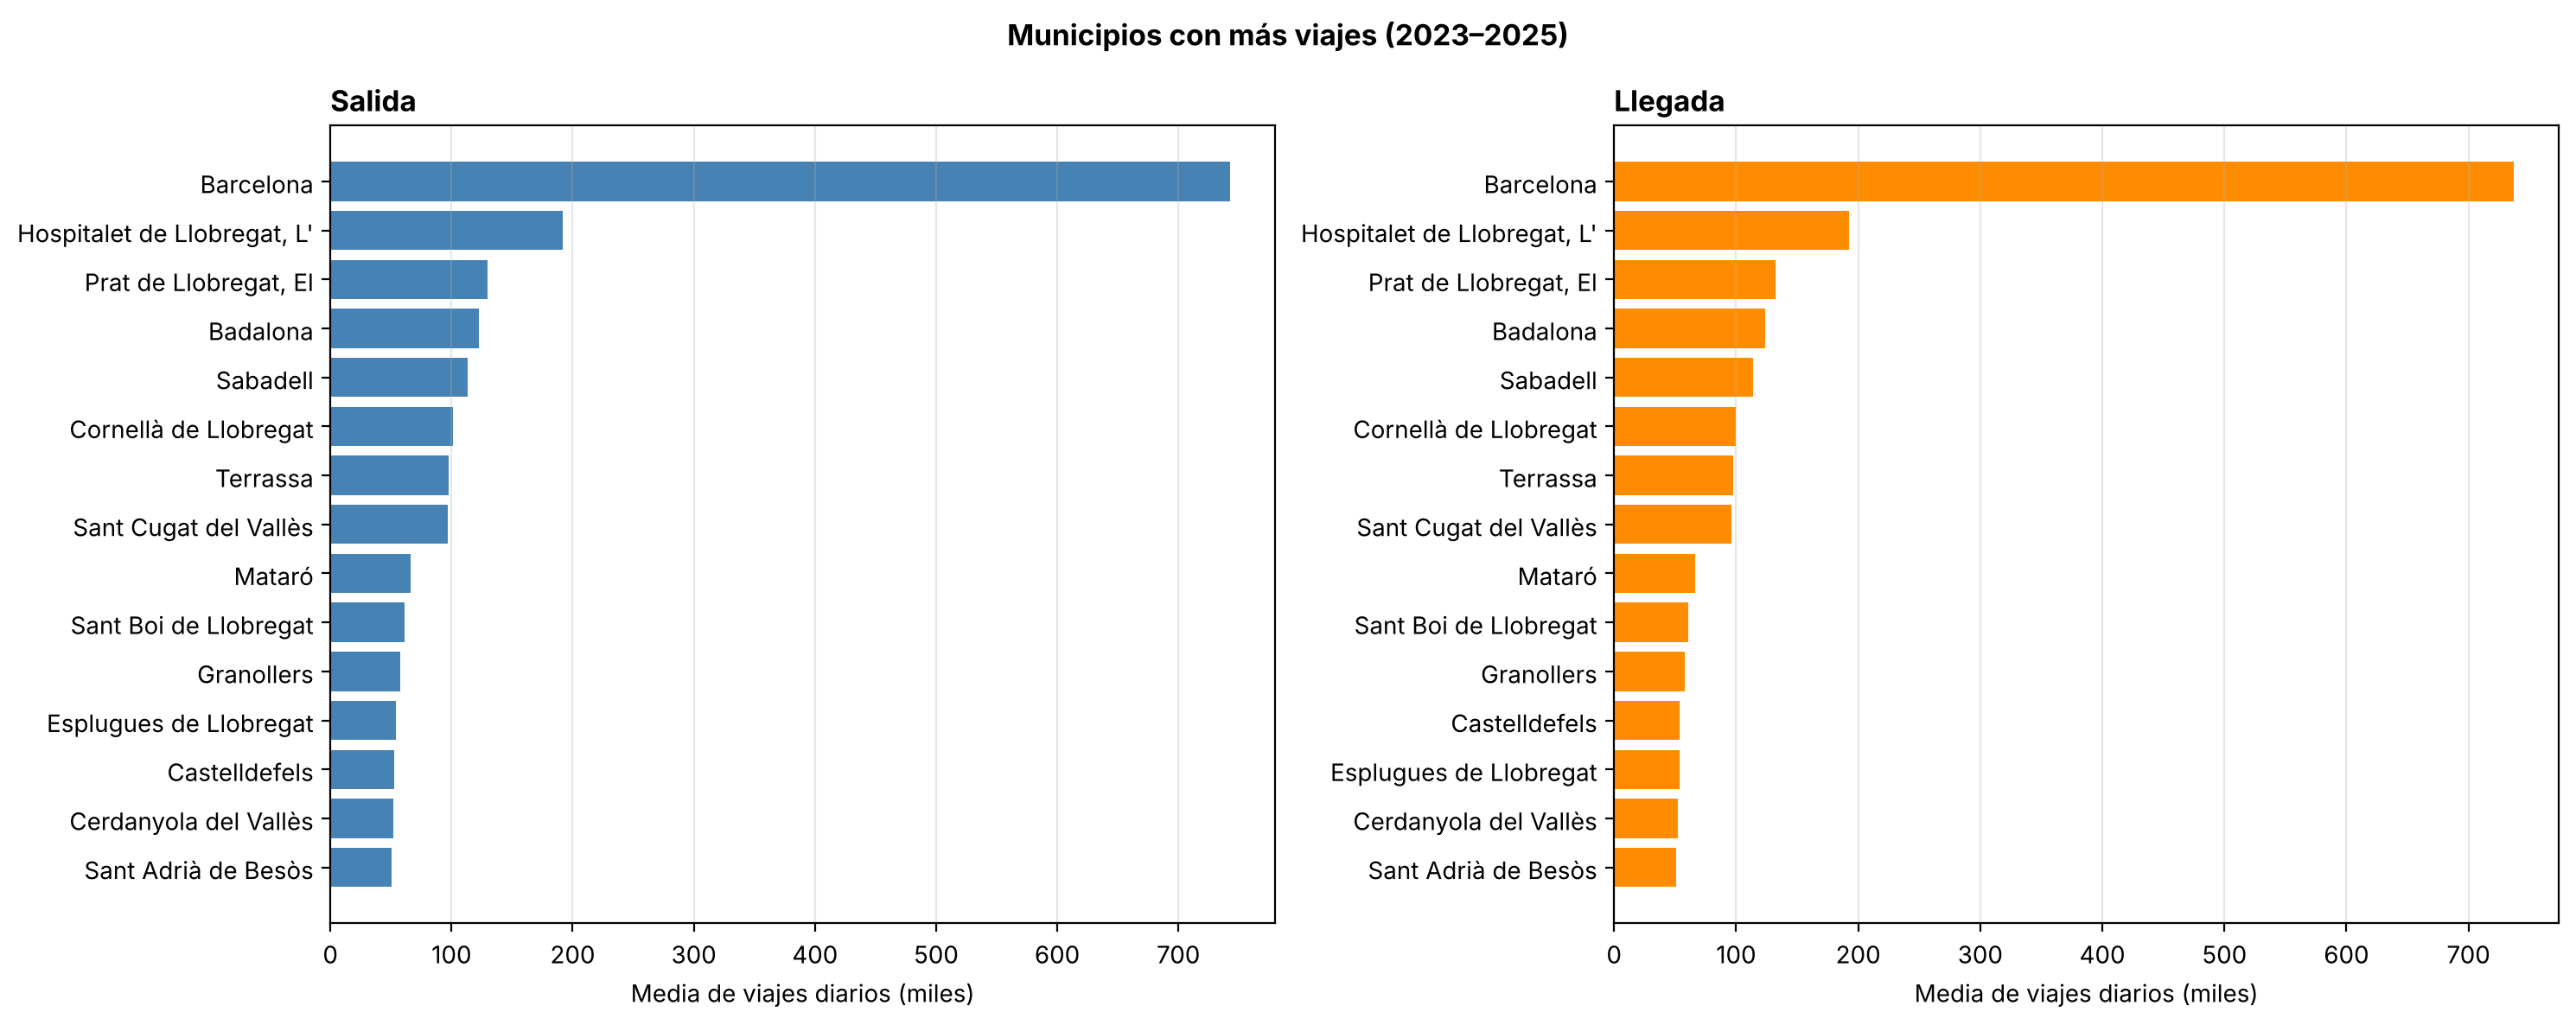

Viajes con origen o destino en Barcelona: 39% del total


In [8]:
def top_municipios(columna):
    return con.execute(f"""
        SELECT {columna}_name AS municipio, SUM(viajes) / {DIAS_DATOS} AS media_diaria
        FROM read_parquet('{MOVILIDAD.as_posix()}')
        GROUP BY {columna}_name ORDER BY media_diaria DESC LIMIT 15""").df()


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (columna, titulo, color) in zip(axes, [("municipio_origen", "Salida", "steelblue"),
                                               ("municipio_destino", "Llegada", "darkorange")]):
    t = top_municipios(columna).iloc[::-1]
    ax.barh(t.municipio, t.media_diaria / 1e3, color=color)
    ax.set_title(titulo, loc="left", fontweight="bold")
    ax.set_xlabel("Media de viajes diarios (miles)")
    ax.grid(axis="x", alpha=.3)
fig.suptitle("Municipios con más viajes (2023–2025)", fontweight="bold")
plt.tight_layout()
plt.show()

total = resumen.viajes.iloc[0]
con_bcn = con.execute(f"""SELECT SUM(viajes) FROM read_parquet('{MOVILIDAD.as_posix()}')
                          WHERE municipio_origen = '08019' OR municipio_destino = '08019'""").fetchall()[0][0]
print(f"Viajes con origen o destino en Barcelona: {con_bcn / total:.0%} del total")

**Resultado.** Barcelona aparece en el **39 %** de los viajes (como origen o destino) y es, de lejos, el municipio con más salidas y llegadas (≈ 740.000 al día en cada sentido). Las relaciones más grandes son las de Barcelona con los municipios vecinos: L'Hospitalet (≈ 109.000 viajes al día en cada sentido), El Prat y Badalona (≈ 60.000). Los volúmenes de ida y vuelta de cada relación son casi iguales. Como el impacto de una incidencia afecta a pocos corredores, hay que analizarlo por relación o por grupo de municipios, no con el total.

## 3. Una primera referencia de «día normal»: la mediana del mismo día de la semana

Para medir el impacto de una incidencia hay que comparar los viajes de ese día con los de un día normal. La primera
opción que se prueba es la más sencilla: **la mediana de los mismos días de la semana de las seis semanas anteriores**.

### 3.1 La regla

- **Días comparables:** mismo día de la semana, dentro de los 42 días anteriores, de lunes a viernes.
- **Se excluyen:** festivos de Cataluña, julio y agosto, y los días del catálogo de incidencias del equipo.
- **Mínimo de 3 días comparables**; si no, no se calcula.
- **Solo días anteriores**: la referencia no usa el propio día ni días posteriores (evaluación «predictiva»).

$$\text{Variación (\%)} = \left(\frac{\text{viajes observados}}{\text{mediana de los días comparables}} - 1\right) \times 100$$

Se prueba en 26 relaciones origen–destino: cinco hacia Barcelona desde municipios con Rodalies (Mataró, Granollers,
La Garriga, Sabadell y Terrassa), Martorell → Granollers y las 20 relaciones entre los cinco municipios del corredor sur
(Barcelona, El Prat, Viladecans, Gavà y Castelldefels; incluye Castelldefels → Barcelona).

In [9]:
festivos = holidays.country_holidays("ES", subdiv="CT", years=ANOS)
fechas_incidencias = set(cargar_catalogo(INCIDENCIAS).date.dropna())

relaciones = {
    "Mataró → Barcelona": ("08121", "08019"), "Granollers → Barcelona": ("08096", "08019"),
    "Castelldefels → Barcelona": ("08056", "08019"), "La Garriga → Barcelona": ("08088", "08019"),
    "Sabadell → Barcelona": ("08187", "08019"), "Terrassa → Barcelona": ("08279", "08019"),
    "Martorell → Granollers": ("08114", "08096"),
}
sur = {"08019": "Barcelona", "08169": "El Prat de Llobregat", "08301": "Viladecans", "08089": "Gavà", "08056": "Castelldefels"}
relaciones |= {f"{no} → {nd}": (o, d) for o, no in sur.items() for d, nd in sur.items() if o != d}
movilidad_od = cargar_relaciones(con, MOVILIDAD, relaciones)
print(f"{movilidad_od.Relacion.nunique()} relaciones · {len(fechas_incidencias)} días con incidencia en el catálogo · "
      f"meses excluidos: {MESES_EXCLUIDOS}")

26 relaciones · 198 días con incidencia en el catálogo · meses excluidos: (7, 8)


### 3.2 ¿Es mejor que otras referencias sencillas?

Se compara la mediana con la **media** y con el **último día comparable**, usando los mismos días comparables, en los
días laborables de 2025 sin festivos ni incidencias del catálogo. Métricas: **MAE** (error medio en viajes), **WAPE**
(error en % del total de viajes) y **sesgo** (si la referencia tiende a quedarse por encima o por debajo).

In [10]:
validacion = evaluar_mediana(movilidad_od, fechas_incidencias, festivos)
# Comprobaciones de la regla: solo días anteriores, ≥ 3 controles, laborables fuera de julio y agosto
assert (validacion.ultima_fecha_control < validacion.day).all() and validacion.n_controles.ge(3).all()
assert validacion.day.dt.day_of_week.lt(5).all() and not validacion.day.dt.month.isin(MESES_EXCLUIDOS).any()

metodos = pd.DataFrame([{"referencia": m, **metricas_referencia(validacion, m)}
                        for m in ["mediana", "media", "ultimo_comparable"]]).set_index("referencia")
display(metodos.round(2))
por_relacion = pd.DataFrame([{"relacion": r, **metricas_referencia(g, "mediana")}
                             for r, g in validacion.groupby("Relacion")]).set_index("relacion")
display(por_relacion.sort_values("WAPE_pct", ascending=False)[["n_fechas", "MAE_viajes", "WAPE_pct", "sesgo_pct"]].round(2))

,n_od_dia,n_fechas,MAE_viajes,WAPE_pct,sesgo_pct
referencia,,,,,
mediana,2054,79,1111.24,8.40,-1.56
media,2054,79,1188.11,8.98,-3.05
ultimo_comparable,2054,79,1268.77,9.59,-1.73


,n_fechas,MAE_viajes,WAPE_pct,sesgo_pct
relacion,,,,
Martorell → Granollers,79,23.90,25.12,-5.49
El Prat de Llobregat → Castelldefels,79,731.13,13.99,-3.40
La Garriga → Barcelona,79,258.41,12.01,1.00
Viladecans → El Prat de Llobregat,79,690.00,11.12,-3.69
El Prat de Llobregat → Viladecans,79,595.66,10.70,-1.49
Gavà → El Prat de Llobregat,79,370.15,10.48,-2.70
Gavà → Viladecans,79,268.98,9.81,-2.82
Castelldefels → El Prat de Llobregat,79,409.63,9.56,-1.74
El Prat de Llobregat → Barcelona,79,6163.20,8.81,-3.05


**Resultado.** La **mediana** es la mejor de las tres referencias: un error del **8,4 %** del total de viajes (MAE de 1.111 viajes), frente al 9,0 % de la media y el 9,6 % del último día comparable. Las tres tienden a quedarse un poco por debajo de lo observado (sesgo entre −1,6 % y −3,1 %). Por relación, 23 de las 26 tienen un error por debajo del 12 %; las que más fallan son las de menos viajes, como Martorell → Granollers (25,1 %).

### 3.3 Caso Mataró → Barcelona

Viajes observados frente a la referencia en los días evaluados de 2025, con la banda del 50 % central (P25–P75) de los
días comparables.

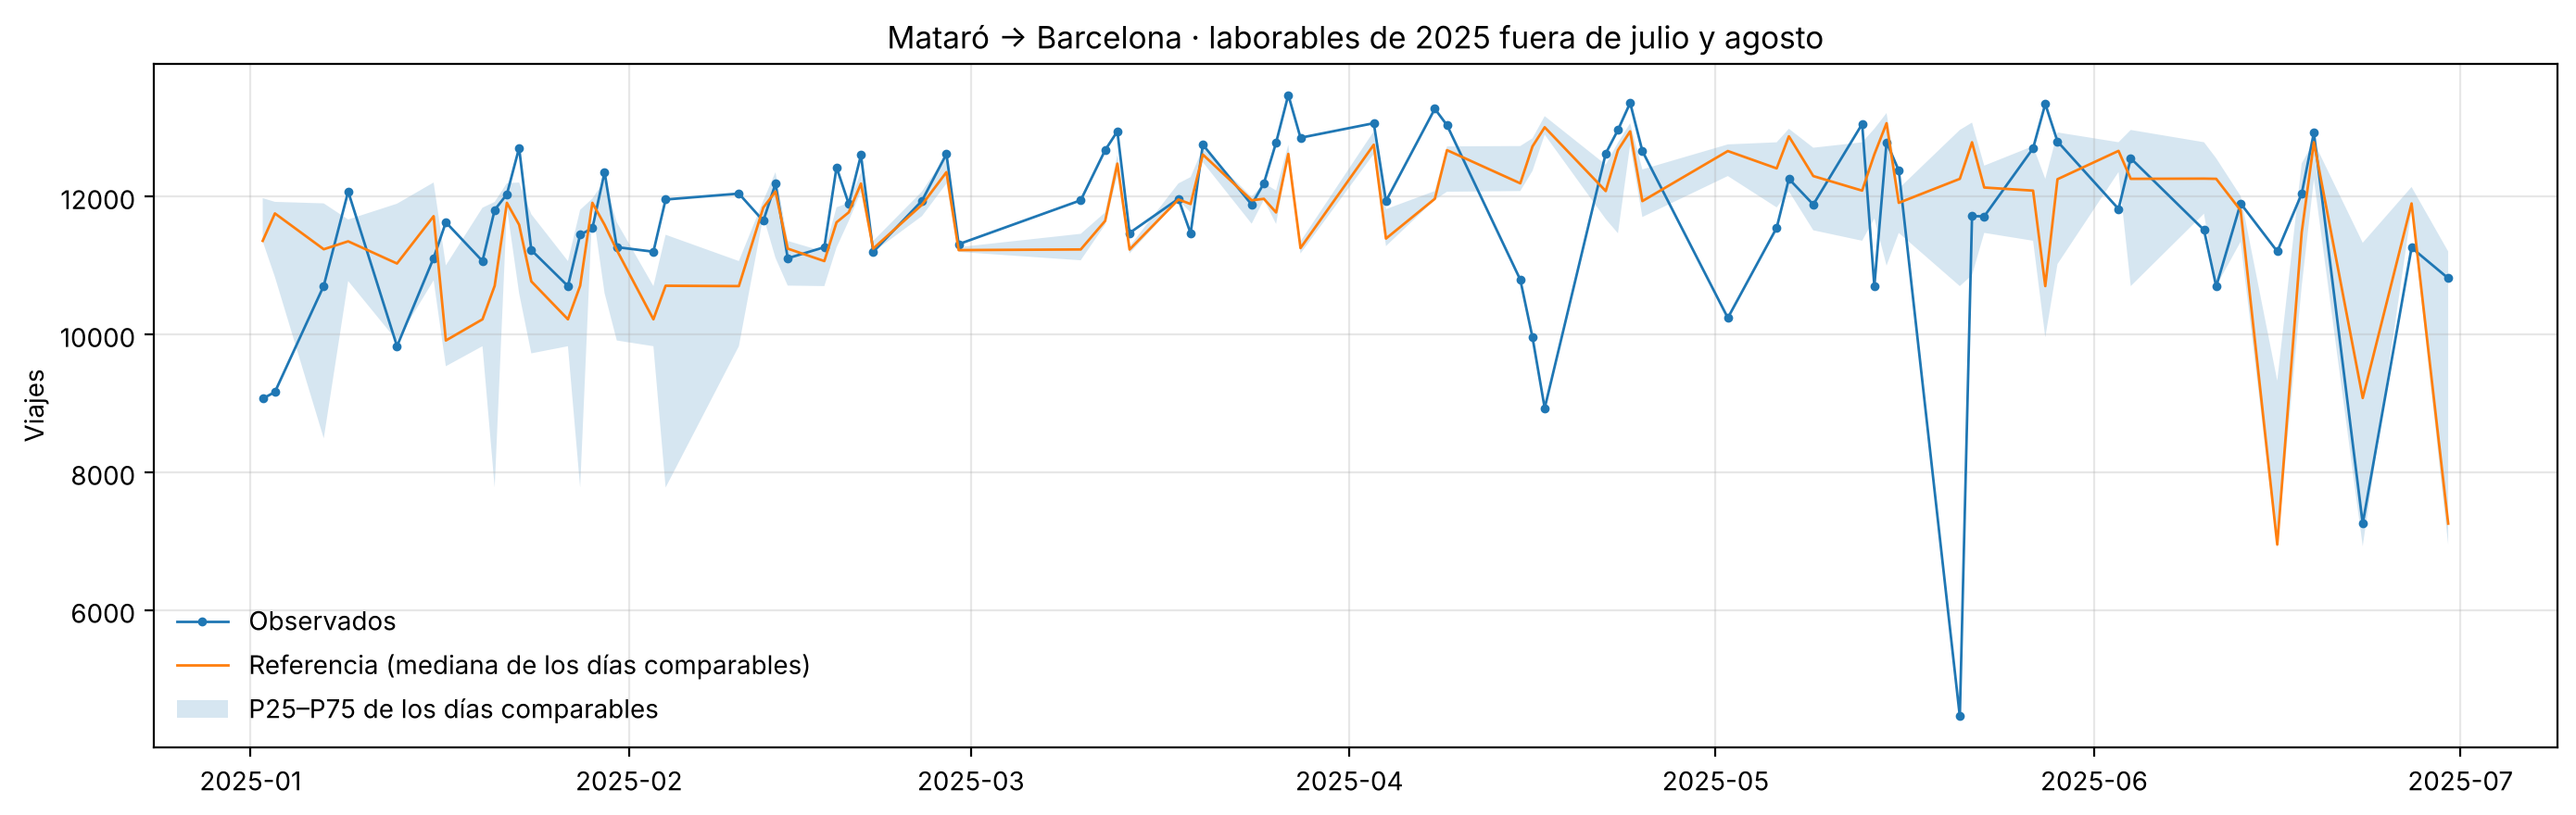

,dia,viajes_observados,mediana,n_controles,variacion_pct
1563,Miércoles 21/05/2025,4462.0,12258.0,5,-63.6
1550,Jueves 17/04/2025,8932.0,13006.0,4,-31.3
1502,Viernes 03/01/2025,9166.0,11756.0,3,-22.0
1549,Miércoles 16/04/2025,9959.0,12728.0,4,-21.8
1501,Jueves 02/01/2025,9069.0,11358.0,3,-20.2
1543,Viernes 28/03/2025,12854.0,11254.0,4,14.2
1507,Viernes 17/01/2025,11628.0,9913.0,3,17.3
1567,Miércoles 28/05/2025,13344.0,10702.0,5,24.7
1579,Lunes 30/06/2025,10816.0,7257.0,5,49.0
1574,Lunes 16/06/2025,11205.0,6953.0,3,61.2


In [11]:
serie = validacion[validacion.Relacion == "Mataró → Barcelona"].sort_values("day")
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(serie.day, serie.viajes_observados, lw=1, marker="o", ms=2.5, label="Observados")
ax.plot(serie.day, serie.mediana, lw=1, label="Referencia (mediana de los días comparables)")
ax.fill_between(serie.day, serie.p25_viajes_controles, serie.p75_viajes_controles, alpha=.18, label="P25–P75 de los días comparables")
ax.set(ylabel="Viajes", title="Mataró → Barcelona · laborables de 2025 fuera de julio y agosto")
ax.legend(frameon=False)
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

serie = serie.assign(variacion_pct=(serie.viajes_observados / serie.mediana - 1) * 100)
extremos = pd.concat([serie.nsmallest(5, "variacion_pct"), serie.nlargest(5, "variacion_pct")]).sort_values("variacion_pct")
display(extremos.assign(dia=extremos.day.map(lambda x: f"{DIAS_SEMANA[x.day_of_week]} {x:%d/%m/%Y}"))
        [["dia", "viajes_observados", "mediana", "n_controles", "variacion_pct"]].round({"mediana": 0, "variacion_pct": 1}))

**¿Qué días se usaron como referencia en los extremos?** Para entender las desviaciones más grandes, se listan los días
comparables de cada una.

In [12]:
from analysis.rmove_indicators import preparar_grupo, seleccionar_controles

g = preparar_grupo(movilidad_od[movilidad_od.Relacion == "Mataró → Barcelona"])
for d in extremos.day.head(2).tolist() + extremos.day.tail(2).tolist():
    c = seleccionar_controles(g, d, fechas_incidencias, festivos, "predictivo")
    print(f"{d:%d/%m/%Y}: {', '.join(f'{x:%d/%m} ({miles(v)})' for x, v in zip(c.day, c.viajes_observados))}")

21/05/2025: 09/04 (13.036), 16/04 (9.959), 23/04 (12.967), 07/05 (12.258), 14/05 (10.702)
17/04/2025: 13/03 (12.947), 20/03 (12.753), 27/03 (13.475), 03/04 (13.065)
30/06/2025: 19/05 (6.852), 26/05 (11.706), 09/06 (6.953), 16/06 (11.205), 23/06 (7.257)
16/06/2025: 19/05 (6.852), 26/05 (11.706), 09/06 (6.953)


**Resultado.** La referencia sigue bien los días normales, pero las desviaciones más grandes **no son incidencias de Rodalies**:
- **Caídas:** el 21/05/2025 (−63,6 %) es un día con un error en los datos (notebook 03, sección A.3); el 16 y el 17/04 son Semana Santa, y el 2 y el 3/01, Navidad. Ninguno es festivo oficial de Cataluña, así que la regla no los excluye.
- **Subidas:** el 16/06 (+61,2 %) y el 30/06 (+49,0 %) no tienen más viajes de lo normal; es la referencia la que es baja, porque sus días comparables incluyen el 19/05 (error en los datos), el 09/06 (festivo local en Barcelona) y el 23/06 (víspera de Sant Joan). El 16/06 solo tiene 3 días comparables. Lo mismo pasa el 28/05, cuya referencia incluye el 21/05.

## 4. Conclusiones

1. **La movilidad depende mucho del calendario.** Día de la semana (domingo −39 % respecto a jueves), mes (agosto −24 %), Navidad, Semana Santa y festivos. Un día solo se puede comparar con días parecidos.
2. **Barcelona es el centro de la red** (39 % de los viajes), y los flujos más grandes son con los municipios vecinos. El impacto de una incidencia hay que medirlo por grupos de municipios, no con el total.
3. **La mediana de los mismos días de la semana es una buena primera referencia** (error del 8,4 %, mejor que la media o el último día comparable), y por eso el notebook 03 sigue usando la mediana.
4. **Pero no basta para medir incidencias.** Sus mayores errores vienen de días raros que la regla no excluye (Semana Santa, Navidad, festivos locales, errores en los datos), en el propio día o en la referencia. Y no puede separar el efecto del tren de lo que le pasa a todo el mundo ese día (lluvia, un día flojo).

**Qué cambia en el notebook 03.**
- Los **días normales** («días limpios») se definen con un calendario completo: festivos de Cataluña y locales de Barcelona, puentes, Navidad, Semana Santa, verano, eventos, lluvia, errores en los datos e incidencias del registro oficial.
- En lugar del mismo día de la semana, cada día se compara con los días limpios **de su mismo tipo** (clustering por volumen y época del año).
- Se añade un **grupo de control** (municipios sin Rodalies) para descontar lo que le pasa a todo el mundo ese día.
- La significancia se mide con **placebos** (días normales tratados como falsos días de caos).